# 1. Understand the data

The task is to predict timely diagnosis, not cancer incidence. Before fitting a model, check who is represented, what is missing, and how the observed diagnosis rate varies by insurance. These descriptive rates are not causal insurance effects. Area characteristics describe locations, not individual patients.

Calculation functions are in [src/analysis.py](../src/analysis.py); this notebook shows the analysis in order, without a second copy of those functions.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.analysis import read_data, explore_data

train, test, sample = read_data()
print("Training shape:", train.shape)
print("Test shape:", test.shape)
display(train["DiagPeriodL90D"].value_counts().rename("patients").to_frame())

Training shape: (12906, 83)
Test shape: (5792, 82)


,patients
DiagPeriodL90D,
1,8060
0,4846


## Missing information

Keep unknown insurance and race explicitly unknown. Filling them with guessed identities would change the meaning of the later group audit. Numerical missing values will be handled by CatBoost.

,training_missing_pct,test_missing_pct
metastatic_first_novel_treatment,99.814040,99.810083
metastatic_first_novel_treatment_type,99.814040,99.810083
bmi,69.463815,69.319751
patient_race,49.473113,50.086326
payer_type,13.970246,13.121547
Division,0.402913,0.362569
Region,0.402913,0.362569
patient_state,0.395165,0.362569
N02,0.224702,0.241713
PM25,0.224702,0.241713


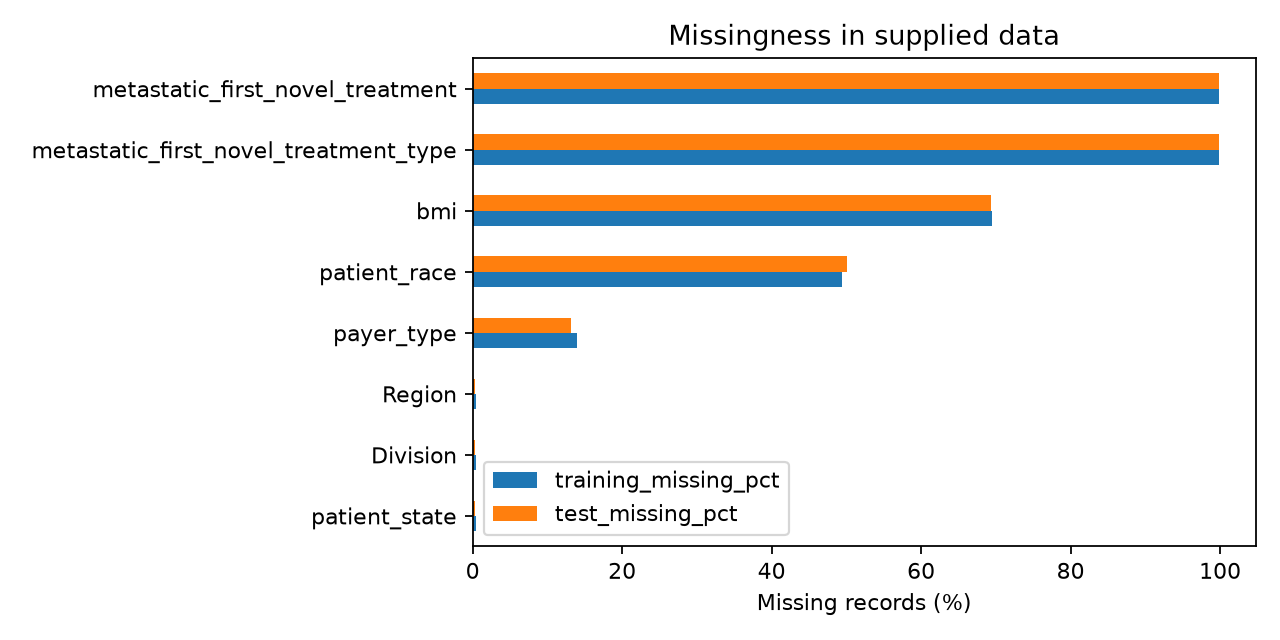

In [2]:
missing, insurance = explore_data(train, test)
display(missing.sort_values("training_missing_pct", ascending=False).head(10))
display(Image(filename=str(ROOT / "reports/images/missingness.png")))

## Observed insurance groups

This table uses all supplied training patients for description. Prediction and threshold selection later use the fixed development split. A difference in these rates does not establish why a difference occurs.

In [3]:
display(insurance)

,patients,timely_diagnosis_rate
insurance,,
COMMERCIAL,6032,0.598806
MEDICAID,2569,0.610354
MEDICARE ADVANTAGE,2502,0.642286
Unknown,1803,0.706045
